# Medical Insurance Cost Prediction

This notebook predicts individual medical insurance charges using a Decision Tree Regressor and Ridge Regression. It includes data inspection, exploratory analysis, leakage-safe preprocessing, five-fold cross-validation, hyperparameter tuning, and test-set evaluation.

**Dataset:** Medical Cost Personal Dataset (`insurance.csv`). The file contains age, sex, BMI, number of children, smoking status, region, and insurance charges.

In [1]:
from pathlib import Path
import os
import warnings

os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## 1. Load and inspect the data

In [2]:
data_path = Path('data/insurance.csv')
insurance = pd.read_csv(data_path)

print(f'Shape: {insurance.shape}')
display(insurance.head())
insurance.info()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [3]:
display(insurance.describe(include='all').T)
print('Missing values by column:')
display(insurance.isna().sum().to_frame('missing'))
print(f'Duplicate rows: {insurance.duplicated().sum()}')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Missing values by column:


,missing
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


Duplicate rows: 1


## 2. Data cleaning

The dataset has no missing values. One exact duplicate is removed so the same record does not receive extra weight. The preprocessing pipelines still contain imputers so the workflow remains robust if a future copy contains missing values.

In [4]:
insurance = insurance.drop_duplicates().reset_index(drop=True)
print(f'Shape after removing duplicates: {insurance.shape}')

Shape after removing duplicates: (1337, 7)


## 3. Exploratory data analysis

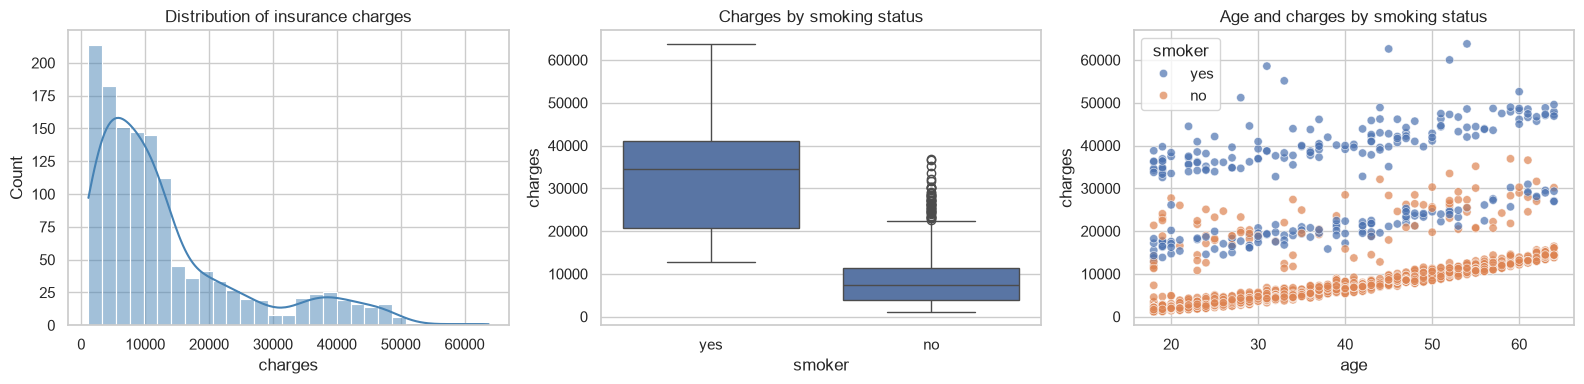

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(insurance['charges'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of insurance charges')
sns.boxplot(data=insurance, x='smoker', y='charges', ax=axes[1])
axes[1].set_title('Charges by smoking status')
sns.scatterplot(data=insurance, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[2])
axes[2].set_title('Age and charges by smoking status')
plt.tight_layout()
plt.show()

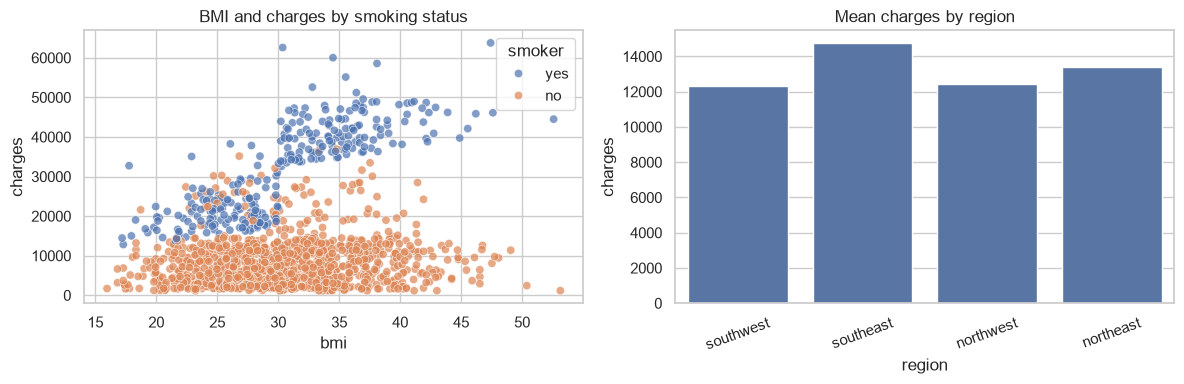

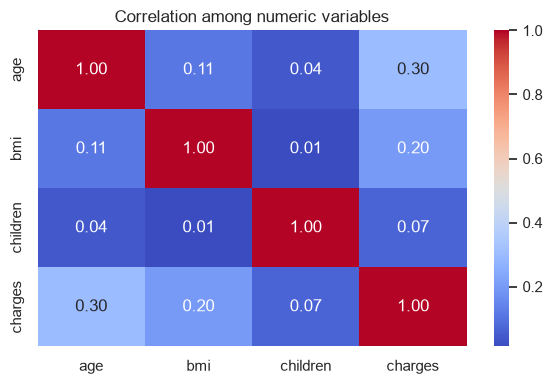

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=insurance, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[0])
axes[0].set_title('BMI and charges by smoking status')
sns.barplot(data=insurance, x='region', y='charges', estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title('Mean charges by region')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

numeric_corr = insurance.select_dtypes(include=np.number).corr()
plt.figure(figsize=(6, 4))
sns.heatmap(numeric_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation among numeric variables')
plt.tight_layout()
plt.show()

## 4. Outlier investigation

The IQR rule flags high charge values. They are retained because the values are plausible medical costs, belong mainly to smokers, and are important outcomes rather than obvious measurement errors. Removing them would change the population the model is intended to predict.

In [7]:
q1, q3 = insurance['charges'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
charge_outliers = insurance[insurance['charges'] > upper_bound]
print(f'IQR upper bound: ${upper_bound:,.2f}')
print(f'Rows above the bound: {len(charge_outliers)} ({len(charge_outliers)/len(insurance):.1%})')
display(pd.crosstab(charge_outliers['smoker'], columns='count'))

IQR upper bound: $34,524.78
Rows above the bound: 139 (10.4%)


col_0,count
smoker,
no,3
yes,136


## 5. Train/test split and preprocessing

The data is split before model fitting. Numeric features are median-imputed and standardized. Categorical features are most-frequent-imputed and one-hot encoded. All transformations are fitted only on the training folds through scikit-learn pipelines.

In [8]:
X = insurance.drop(columns='charges')
y = insurance['charges']

numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f'Training rows: {len(X_train)} | Test rows: {len(X_test)}')

Training rows: 1069 | Test rows: 268


## 6. Hyperparameter tuning

GridSearchCV uses five-fold cross-validation and negative RMSE as the selection score. The grids are intentionally compact and easy to explain.

In [9]:
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))
])
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

tree_grid = {
    'model__max_depth': [3, 4, 5, 6, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5, 10]
}
ridge_grid = {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}

tree_search = GridSearchCV(tree_pipeline, tree_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=1)
ridge_search = GridSearchCV(ridge_pipeline, ridge_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=1)

tree_search.fit(X_train, y_train)
ridge_search.fit(X_train, y_train)

print('Decision Tree best parameters:', tree_search.best_params_)
print(f'Decision Tree CV RMSE: {-tree_search.best_score_:,.2f}')
print('Ridge best parameters:', ridge_search.best_params_)
print(f'Ridge CV RMSE: {-ridge_search.best_score_:,.2f}')

Decision Tree best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Decision Tree CV RMSE: 4,768.15
Ridge best parameters: {'model__alpha': 1.0}
Ridge CV RMSE: 6,113.33


## 7. Test-set evaluation

In [10]:
def evaluate_model(name, fitted_model):
    predictions = fitted_model.predict(X_test)
    return {
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': mean_squared_error(y_test, predictions) ** 0.5,
        'R2': r2_score(y_test, predictions),
        'Predictions': predictions
    }

tree_result = evaluate_model('Decision Tree', tree_search.best_estimator_)
ridge_result = evaluate_model('Ridge Regression', ridge_search.best_estimator_)

results = pd.DataFrame([
    {k: v for k, v in tree_result.items() if k != 'Predictions'},
    {k: v for k, v in ridge_result.items() if k != 'Predictions'}
]).set_index('Model')
display(results.style.format({'MAE': '${:,.2f}', 'RMSE': '${:,.2f}', 'R2': '{:.4f}'}))

,MAE,RMSE,R2
Model,,,
Decision Tree,"$2,613.67","$4,303.54",0.8992
Ridge Regression,"$4,185.41","$5,964.28",0.8064


## 8. Actual versus predicted charges

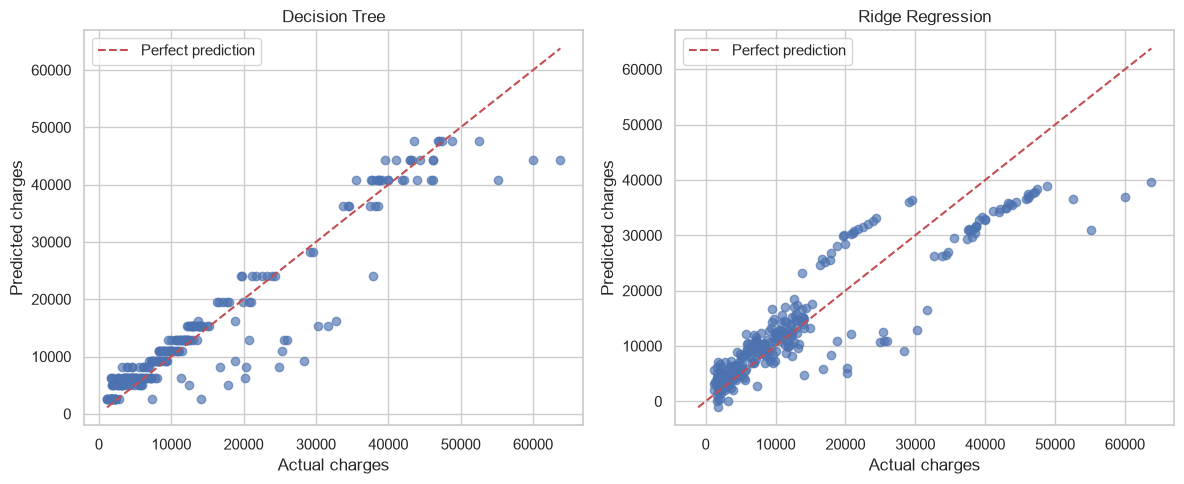

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, result, title in zip(
    axes, [tree_result, ridge_result], ['Decision Tree', 'Ridge Regression']
):
    ax.scatter(y_test, result['Predictions'], alpha=0.65)
    low = min(y_test.min(), result['Predictions'].min())
    high = max(y_test.max(), result['Predictions'].max())
    ax.plot([low, high], [low, high], 'r--', label='Perfect prediction')
    ax.set_xlabel('Actual charges')
    ax.set_ylabel('Predicted charges')
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Conclusion

In [12]:
best_model = results['RMSE'].idxmin()
best_row = results.loc[best_model]
print(f'Best model: {best_model}')
print(f"It achieved the lowest test RMSE (${best_row['RMSE']:,.2f}) and an R² of {best_row['R2']:.4f}.")
if best_model == 'Decision Tree':
    print('The tree captures non-linear relationships and interactions, especially the strong effect of smoking status.')
else:
    print('Ridge performed best because the regularized linear relationship generalized well to the held-out data.')

Best model: Decision Tree
It achieved the lowest test RMSE ($4,303.54) and an R² of 0.8992.
The tree captures non-linear relationships and interactions, especially the strong effect of smoking status.
